# Crowd Management — YOLO Training + Counting + PERSON1/PERSON2 Tracking

**Dataset:** Kaggle `sbaghbidi/human-faces-object-detection`

This notebook downloads the dataset, converts its `faces.csv` bounding boxes to YOLO format, trains YOLO11n, validates it, and provides video/camera tracking code using ByteTrack.

**Important:** this Kaggle dataset is a *face detection* dataset. Therefore the trained model counts visible faces. It will not reliably count a person whose face is completely hidden. For true full-body crowd counting, use full-body `person` annotations.


## 1. Install dependencies

In [2]:
!pip install -q -U ultralytics kagglehub pandas pyyaml opencv-python matplotlib scikit-learn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 6.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 47.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 116.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 111.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 103.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.0/96.0 kB 9.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
dask-cu

## 2. Download the exact Kaggle dataset

In [3]:
import os, kagglehub
from pathlib import Path

DATASET_ID = "sbaghbidi/human-faces-object-detection"
path = kagglehub.dataset_download(DATASET_ID)
dataset_root = Path(path)

print("Dataset path:", dataset_root)
for root, dirs, files in os.walk(dataset_root):
    level = root.replace(str(dataset_root), "").count(os.sep)
    if level <= 2:
        print("  "*level + os.path.basename(root) + "/")
        for f in files[:10]:
            print("  "*(level+1) + f)


100%|██████████| 498M/498M [00:03<00:00, 133MB/s]

Extracting files...


Dataset path: /root/.cache/kagglehub/datasets/sbaghbidi/human-faces-object-detection/versions/1
1/
  faces.csv
  images/
    00001528.jpg
    00002297.jpg
    00000114.jpg
    00000118.jpg
    00001794.jpg
    00001399.jpg
    00000604.jpg
    00001926.jpg
    00002180.jpg
    00000181.jpg


## 3. Load and inspect the annotation CSV

The dataset uses a CSV with face bounding-box information. The expected fields are:

`image_name, width, height, x0, y0, x1, y1`


In [4]:
import pandas as pd

csv_candidates = list(dataset_root.rglob("faces.csv"))
if not csv_candidates:
    csv_candidates = list(dataset_root.rglob("*.csv"))
if not csv_candidates:
    raise FileNotFoundError("No annotation CSV found.")

csv_path = csv_candidates[0]
df = pd.read_csv(csv_path)

print("CSV:", csv_path)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


CSV: /root/.cache/kagglehub/datasets/sbaghbidi/human-faces-object-detection/versions/1/faces.csv
Shape: (3350, 7)
Columns: ['image_name', 'width', 'height', 'x0', 'y0', 'x1', 'y1']


,image_name,width,height,x0,y0,x1,y1
0,00001722.jpg,1333,2000,490,320,687,664
1,00001044.jpg,2000,1333,791,119,1200,436
2,00001050.jpg,667,1000,304,155,407,331
3,00001736.jpg,626,417,147,14,519,303
4,00003121.jpg,626,418,462,60,599,166


## 4. Find the images and verify annotations

In [5]:
import os
from pathlib import Path

image_dirs = [p for p in dataset_root.rglob("*") if p.is_dir() and p.name.lower() == "images"]
if not image_dirs:
    raise FileNotFoundError("No images directory found.")
image_root = image_dirs[0]

df["image_name"] = df["image_name"].astype(str).map(os.path.basename)

available_images = {}
for p in image_root.rglob("*"):
    if p.is_file() and p.suffix.lower() in {".jpg",".jpeg",".png",".bmp",".webp"}:
        available_images[p.name] = p

print("Image directory:", image_root)
print("Images found:", len(available_images))
print("CSV rows:", len(df))

missing = sorted(set(df["image_name"]) - set(available_images))
print("Missing referenced images:", len(missing))
print(missing[:10])


Image directory: /root/.cache/kagglehub/datasets/sbaghbidi/human-faces-object-detection/versions/1/images
Images found: 2204
CSV rows: 3350
Missing referenced images: 0
[]


## 5. Convert CSV boxes to YOLO format and create train/val/test splits

YOLO labels use:

`class_id x_center y_center width height`

with normalized coordinates from 0 to 1.

We use one class: `0 = person`. The boxes themselves are face boxes from this dataset.


In [6]:
from pathlib import Path
import random, shutil, yaml

OUT = Path("/content/crowd_face_yolo")
if OUT.exists():
    shutil.rmtree(OUT)

for split in ["train","val","test"]:
    (OUT/"images"/split).mkdir(parents=True, exist_ok=True)
    (OUT/"labels"/split).mkdir(parents=True, exist_ok=True)

required = ["image_name","width","height","x0","y0","x1","y1"]
missing_cols = [c for c in required if c not in df.columns]
if missing_cols:
    raise ValueError(f"Missing columns: {missing_cols}")

for c in required[1:]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df = df.dropna(subset=required)
df = df[df["image_name"].isin(available_images)]

names = sorted(df["image_name"].unique())
random.seed(42)
random.shuffle(names)

n = len(names)
n_train = int(n*0.80)
n_val = int(n*0.10)

train_names = set(names[:n_train])
val_names = set(names[n_train:n_train+n_val])
test_names = set(names[n_train+n_val:])

def split_name(name):
    return "train" if name in train_names else ("val" if name in val_names else "test")

for name in names:
    split = split_name(name)
    shutil.copy2(available_images[name], OUT/"images"/split/name)

    rows = df[df["image_name"] == name]
    labels = []

    for _, r in rows.iterrows():
        W,H = float(r["width"]), float(r["height"])
        x0,y0,x1,y1 = map(float,[r["x0"],r["y0"],r["x1"],r["y1"]])

        x0,x1 = max(0,min(x0,W)), max(0,min(x1,W))
        y0,y1 = max(0,min(y0,H)), max(0,min(y1,H))
        bw,bh = x1-x0, y1-y0
        if bw <= 1 or bh <= 1:
            continue

        xc = ((x0+x1)/2)/W
        yc = ((y0+y1)/2)/H
        nw = bw/W
        nh = bh/H
        labels.append(f"0 {xc:.6f} {yc:.6f} {nw:.6f} {nh:.6f}")

    (OUT/"labels"/split/(Path(name).stem+".txt")).write_text("\n".join(labels))

data_yaml = {
    "path": str(OUT),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {0:"person"}
}
yaml_path = OUT/"data.yaml"
yaml_path.write_text(yaml.safe_dump(data_yaml, sort_keys=False))

print(f"Total images: {n}")
print(f"Train: {len(train_names)} | Val: {len(val_names)} | Test: {len(test_names)}")
print(yaml_path.read_text())


Total images: 2204
Train: 1763 | Val: 220 | Test: 221
path: /content/crowd_face_yolo
train: images/train
val: images/val
test: images/test
names:
  0: person



## 6. Visual check of converted annotations

Do not skip this step. If the boxes look correct, proceed to training.


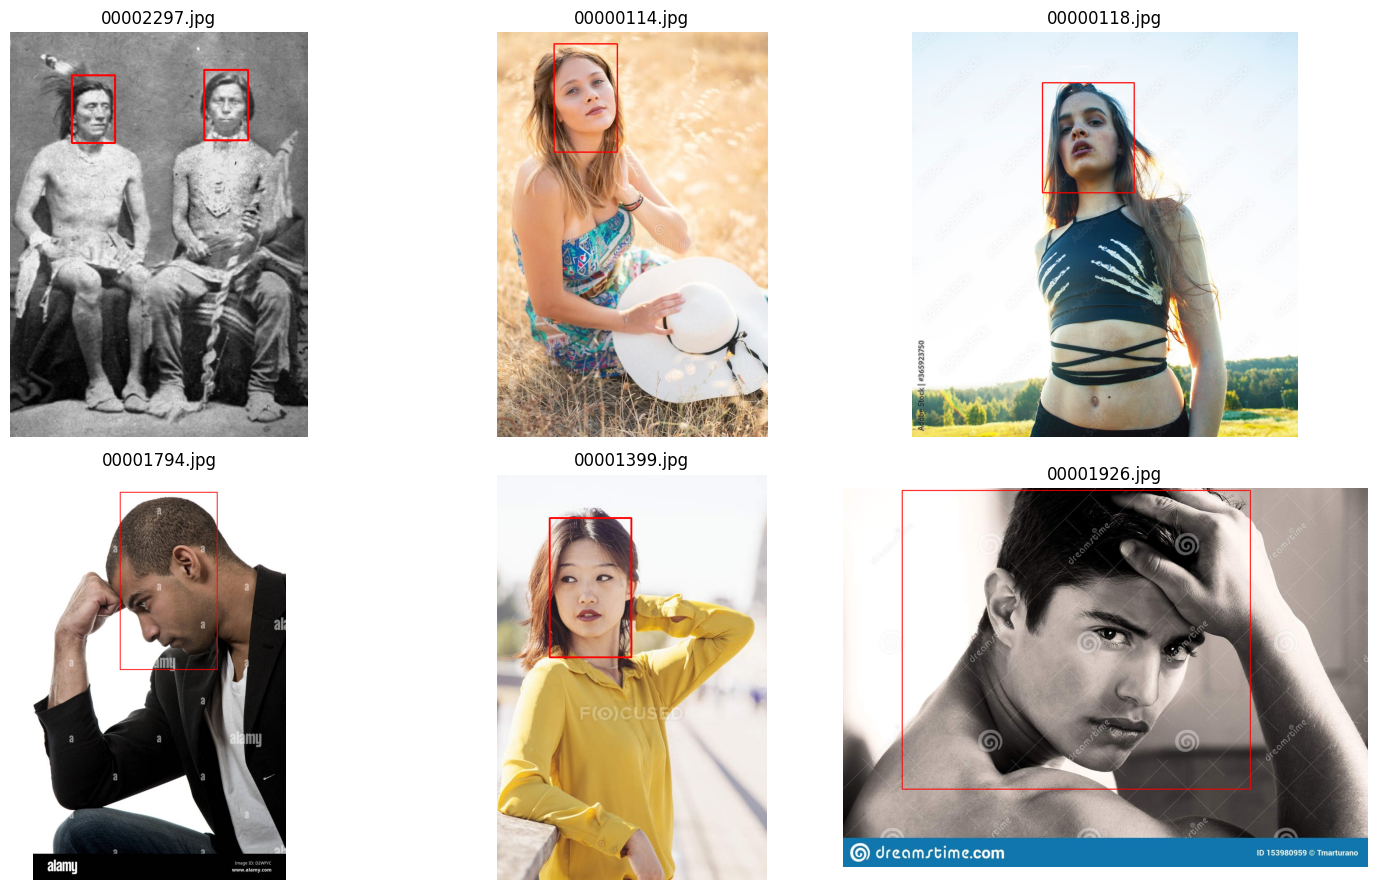

In [7]:
import cv2, matplotlib.pyplot as plt

sample_files = list((OUT/"images"/"train").glob("*"))[:6]
fig, axes = plt.subplots(2,3,figsize=(15,9))
axes = axes.ravel()

for ax, p in zip(axes, sample_files):
    img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    H,W = img.shape[:2]
    lp = OUT/"labels"/"train"/(p.stem+".txt")

    if lp.exists():
        for line in lp.read_text().splitlines():
            parts = line.split()
            if len(parts) != 5: continue
            _,xc,yc,bw,bh = map(float,parts)
            x0,y0 = int((xc-bw/2)*W), int((yc-bh/2)*H)
            x1,y1 = int((xc+bw/2)*W), int((yc+bh/2)*H)
            cv2.rectangle(img,(x0,y0),(x1,y1),(255,0,0),2)

    ax.imshow(img)
    ax.set_title(p.name)
    ax.axis("off")

for ax in axes[len(sample_files):]:
    ax.axis("off")
plt.tight_layout()


## 7. Train YOLO11n

YOLO training uses the custom `data.yaml`. Starting from pretrained weights is recommended for custom detection tasks.

For the first run use 50 epochs. If the validation results continue improving, increase the epochs later.


In [8]:
from ultralytics import YOLO
import torch

device = 0 if torch.cuda.is_available() else "cpu"
print("Torch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

model = YOLO("yolo11n.pt")

results = model.train(
    data=str(yaml_path),
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    project="/content/crowd_management_runs",
    name="yolo11n_face_crowd",
    pretrained=True,
    patience=15,
    plots=True
)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Torch: 2.11.0+cu130
CUDA: True
Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/crowd_face_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.

## 8. Validate and locate `best.pt`

In [9]:
from pathlib import Path
from ultralytics import YOLO

best_pt = Path("/content/crowd_management_runs/yolo11n_face_crowd/weights/best.pt")
assert best_pt.exists(), f"Missing {best_pt}"

trained = YOLO(str(best_pt))
metrics = trained.val(data=str(yaml_path), imgsz=640, device=device, plots=True)

print("BEST MODEL:", best_pt)


Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,582,347 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2120.8±1179.1 MB/s, size: 66.3 KB)
val: Scanning /content/crowd_face_yolo/labels/val.cache... 220 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 220/220 46.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 3.5it/s 4.1s
                   all        220        362      0.896      0.949      0.956        0.7
Speed: 2.3ms preprocess, 6.2ms inference, 0.0ms loss, 2.1ms postprocess per image
Results saved to /content/runs/detect/val
BEST MODEL: /content/crowd_management_runs/yolo11n_face_crowd/weights/best.pt


## 9. Test detection on one test image

Detections: 3


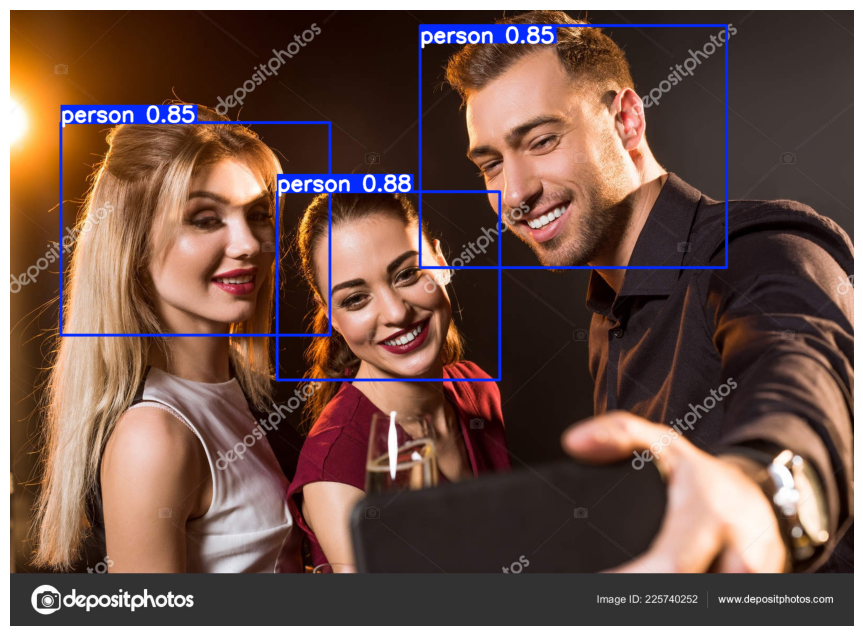

In [10]:
import cv2, matplotlib.pyplot as plt

test_images = list((OUT/"images"/"test").glob("*"))
test_image = str(test_images[0])

pred = trained.predict(test_image, conf=0.35, imgsz=640, device=device, verbose=False)
print("Detections:", len(pred[0].boxes))

annotated = pred[0].plot()
plt.figure(figsize=(14,8))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()


## 10. Crowd tracking: PERSON1, PERSON2, ...

Detection alone gives boxes per frame. Tracking associates boxes over time.

We use **ByteTrack** and map its anonymous track IDs to:

`PERSON1`, `PERSON2`, `PERSON3`, ...

The current count is the number of active tracked people in the current frame.


In [11]:
from ultralytics import YOLO

def run_crowd_video(video_source, output_path="/content/crowd_output.mp4",
                    conf=0.35, imgsz=640):
    model = YOLO(str(best_pt))
    cap = cv2.VideoCapture(video_source)
    if not cap.isOpened():
        raise RuntimeError(f"Could not open {video_source}")

    fps = cap.get(cv2.CAP_PROP_FPS) or 25
    W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    writer = cv2.VideoWriter(output_path, cv2.VideoWriter_fourcc(*"mp4v"), fps, (W,H))

    track_to_person = {}
    next_person = 1
    all_seen = set()

    while True:
        ok, frame = cap.read()
        if not ok:
            break

        r = model.track(frame, persist=True, tracker="bytetrack.yaml",
                         conf=conf, imgsz=imgsz, classes=[0], verbose=False)

        active = set()

        if r[0].boxes is not None and r[0].boxes.id is not None:
            boxes = r[0].boxes.xyxy.cpu().numpy()
            tids = r[0].boxes.id.cpu().numpy().astype(int)
            scores = r[0].boxes.conf.cpu().numpy()

            for box, tid, score in zip(boxes,tids,scores):
                if tid not in track_to_person:
                    track_to_person[tid] = f"PERSON{next_person}"
                    next_person += 1

                name = track_to_person[tid]
                active.add(name)
                all_seen.add(name)

                x0,y0,x1,y1 = map(int,box)
                cv2.rectangle(frame,(x0,y0),(x1,y1),(0,255,0),2)
                cv2.putText(frame,f"{name} {score:.2f}",
                            (x0,max(25,y0-8)),
                            cv2.FONT_HERSHEY_SIMPLEX,0.65,(0,255,0),2)

        cv2.rectangle(frame,(10,10),(430,90),(0,0,0),-1)
        cv2.putText(frame,f"CURRENT PEOPLE: {len(active)}",(20,45),
                    cv2.FONT_HERSHEY_SIMPLEX,0.8,(255,255,255),2)
        cv2.putText(frame,f"UNIQUE SEEN: {len(all_seen)}",(20,75),
                    cv2.FONT_HERSHEY_SIMPLEX,0.7,(255,255,255),2)

        writer.write(frame)

    cap.release()
    writer.release()
    print("Saved:", output_path)
    print("Unique tracked people:", len(all_seen))
    return output_path

# Example:
# run_crowd_video("/content/your_video.mp4")


## 11. Download `best.pt`

After training, this is the file you deploy to the Jetson:

```text
best.pt
```


In [12]:
import shutil
deploy_model = Path("/content/best.pt")
shutil.copy2(best_pt, deploy_model)
print(deploy_model)


/content/best.pt


# 12. Jetson Orin Nano + Logitech camera deployment

On your Jetson, place the trained model here:

```text
~/crowd_detection/best.pt
```

Then create:

```text
~/crowd_detection/crowd_system.py
```

Use OpenCV/V4L2 directly for the Logitech camera (`/dev/video0`). This avoids the webcam-device handling problem you encountered with the Ultralytics CLI.


In [ ]:
# Save the following as ~/crowd_detection/crowd_system.py on the Jetson.

JETSON_CODE = r"""
import cv2
from ultralytics import YOLO

MODEL = "best.pt"
model = YOLO(MODEL)

cap = cv2.VideoCapture(0, cv2.CAP_V4L2)
cap.set(cv2.CAP_PROP_FOURCC, cv2.VideoWriter_fourcc(*"MJPG"))
cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)
cap.set(cv2.CAP_PROP_FPS, 30)

if not cap.isOpened():
    raise RuntimeError("Could not open Logitech camera /dev/video0")

track_to_person = {}
next_person = 1

while True:
    ok, frame = cap.read()
    if not ok:
        print("Camera frame read failed")
        break

    r = model.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        conf=0.35,
        imgsz=640,
        classes=[0],
        verbose=False
    )

    active = set()

    if r[0].boxes is not None and r[0].boxes.id is not None:
        boxes = r[0].boxes.xyxy.cpu().numpy()
        tids = r[0].boxes.id.cpu().numpy().astype(int)
        scores = r[0].boxes.conf.cpu().numpy()

        for box, tid, score in zip(boxes,tids,scores):
            if tid not in track_to_person:
                track_to_person[tid] = f"PERSON{next_person}"
                next_person += 1

            name = track_to_person[tid]
            active.add(name)

            x0,y0,x1,y1 = map(int,box)
            cv2.rectangle(frame,(x0,y0),(x1,y1),(0,255,0),2)
            cv2.putText(frame,f"{name} {score:.2f}",
                        (x0,max(25,y0-8)),
                        cv2.FONT_HERSHEY_SIMPLEX,0.65,(0,255,0),2)

    cv2.rectangle(frame,(10,10),(430,90),(0,0,0),-1)
    cv2.putText(frame,f"CURRENT PEOPLE: {len(active)}",(20,45),
                cv2.FONT_HERSHEY_SIMPLEX,0.8,(255,255,255),2)
    cv2.putText(frame,"Press Q to quit",(20,75),
                cv2.FONT_HERSHEY_SIMPLEX,0.55,(255,255,255),1)

    cv2.imshow("Crowd Management",frame)

    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

cap.release()
cv2.destroyAllWindows()
"""

print(JETSON_CODE)



import cv2
from ultralytics import YOLO

MODEL = "best.pt"
model = YOLO(MODEL)

cap = cv2.VideoCapture(0, cv2.CAP_V4L2)
cap.set(cv2.CAP_PROP_FOURCC, cv2.VideoWriter_fourcc(*"MJPG"))
cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)
cap.set(cv2.CAP_PROP_FPS, 30)

if not cap.isOpened():
    raise RuntimeError("Could not open Logitech camera /dev/video0")

track_to_person = {}
next_person = 1

while True:
    ok, frame = cap.read()
    if not ok:
        print("Camera frame read failed")
        break

    r = model.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        conf=0.35,
        imgsz=640,
        classes=[0],
        verbose=False
    )

    active = set()

    if r[0].boxes is not None and r[0].boxes.id is not None:
        boxes = r[0].boxes.xyxy.cpu().numpy()
        tids = r[0].boxes.id.cpu().numpy().astype(int)
        scores = r[0].boxes.conf.cpu().numpy()

        for box, tid, score in zip(boxes,tids,scores):

# 13. Final architecture

```text
Kaggle Human Faces Dataset
        |
        v
faces.csv + images
        |
        v
CSV -> YOLO labels
        |
        v
Train / Val / Test split
        |
        v
YOLO11n training
        |
        v
best.pt
        |
        v
Jetson Orin Nano + Logitech Camera
        |
        v
YOLO face/person detection
        |
        v
ByteTrack
        |
        +--> PERSON1
        +--> PERSON2
        +--> PERSON3
        |
        v
Current Crowd Count
        |
        +--> Unique people seen
        +--> Entry / Exit counting
        +--> Density zones
        +--> Alerts / logging
```

### What you have after this notebook

1. A custom trained `best.pt`
2. Object detection
3. Bounding boxes
4. Anonymous persistent IDs
5. Current crowd count
6. Unique tracked-person count
7. Video processing
8. Jetson webcam deployment code

### Important next improvement

Because the selected Kaggle dataset contains **face boxes**, the next model iteration should use a **full-body person detection dataset** if the requirement is to count people even when their faces are not visible.
